**Imports**

from example notebook

In [ ]:
import gzip, json
import pandas as pd

spec_files = pd.read_parquet('data/spec_files.parquet')
features = pd.read_parquet('data/spec_content_features.parquet')
prs = pd.read_parquet('data/pull_requests.parquet')
pr_files = pd.read_parquet('data/pr_files.parquet')
links = pd.read_parquet('data/spec_links.parquet')
kiro = pd.read_parquet('data/kiro_files.parquet')
print(f'{len(spec_files):,} specs across {spec_files.repo_name.nunique():,} repos')

**Filter Specs**

keep specs that are English, meet minimum content quantity and quality requirements

In [ ]:
features_copy = features.copy()
# Filter non-English
english = features_copy[features_copy["lang"].eq("en")].copy()
print(len(features_copy), "Original specs")
print(len(english), "English specs")
#print(f"{(features_copy["lang"].eq("en").mean() * 100):.4f}", "% Original classified as English")
# Filter empty or nearly empty specs
usable = english[
    (english["n_words"] >= 100) &
    (english["n_lines"] >= 10) &
    (english["n_headings"] >= 2)
].copy()
print(len(usable), "English specs meeting minimum num words, lines, headings")
#print(f"{(len(usable) / len(english) * 100):.4f}", "% English specs deemed usable")
# Filter specs with placeholders or unfinished material
usable = usable[
    (usable["has_lorem"].fillna(0) == 0) &
    (usable["has_unfilled_placeholder"].fillna(0) == 0)
].copy()
print(len(usable), "Usable specs without placeholders")
# Require minimum of spec quality features
requirement_features = [
    "has_requirements",
    "has_acceptance_criteria",
    "has_user_scenarios",
    "has_success_criteria",
    "has_purpose",
    "has_overview",
    "has_edge_cases",
    "has_dependencies"
]

usable["n_substantive_sections"] = (
    usable[requirement_features]
    .fillna(0)
    .sum(axis=1)
)

eligible = usable[
    usable["n_substantive_sections"] >= 2
].copy()

print(len(eligible), "Eligible specs with 2+ quality features")

display(
    usable[
        ["n_substantive_sections"]
    ].describe(
        percentiles=[
            .01, .05, .10, .25,
            .50, .75, .90, .95, .99
        ]
    )
)


**Spec content quantity distribution**

In [ ]:
display(
    english[
        ["n_words", "n_lines", "n_headings"]
    ].describe(
        percentiles=[
            .01, .05, .10, .25,
            .50, .75, .90, .95, .99
        ]
    )
)

In [84]:
# Load the relevant tables
pull_requests = prs

# PR identity must include all three fields.
PR_KEY = ["tool", "repo_name", "pr_number"]

# --------------------------------------------------
# 2. Prepare eligible spec metadata
# --------------------------------------------------

# eligible is the DataFrame produced by your earlier filtering.
spec_meta = eligible[["file_url_sha16"]].merge(
    spec_files[
        ["file_url_sha16", "repo_name", "file_path", "spec_tool"]
    ],
    on="file_url_sha16",
    how="left"
).rename(columns={"spec_tool": "tool"})

# Remove specs without repository/path metadata.
spec_meta = spec_meta.dropna(
    subset=["tool", "repo_name", "file_path"]
).drop_duplicates("file_url_sha16")

# --------------------------------------------------
# 3. Find initial implementation PRs
# --------------------------------------------------

# PRs that modified an eligible spec file.
spec_changes = pr_files[pr_files["is_spec"].eq(1)].merge(
    spec_meta,
    on=["tool", "repo_name", "file_path"],
    how="inner"
)

# Add PR metadata.
pr_metadata = pull_requests[
    PR_KEY + ["merged_at", "is_merged", "touches_code"]
].drop_duplicates(PR_KEY)

spec_changes = spec_changes.merge(
    pr_metadata,
    on=PR_KEY,
    how="inner"
)

# Keep merged PRs that also changed source code.
initial_candidates = spec_changes[
    (spec_changes["is_merged"].eq(1)) &
    (spec_changes["touches_code"].eq(1))
].copy()

initial_candidates["merged_at"] = pd.to_datetime(
    initial_candidates["merged_at"], errors="coerce", utc=True
)

initial_candidates = initial_candidates.dropna(subset=["merged_at"])

# Select the earliest qualifying PR for each spec.
initial_candidates = initial_candidates.sort_values("merged_at")

initial_prs = (
    initial_candidates
    .drop_duplicates("file_url_sha16")
    [["file_url_sha16"] + PR_KEY + ["merged_at"]]
    .rename(columns={
        "pr_number": "initial_pr",
        "merged_at": "initial_date"
    })
)

print("Specs with an identified initial implementation:",
      f"{len(initial_prs):,}")

# --------------------------------------------------
# 4. Identify code paths changed by each initial PR
# --------------------------------------------------

initial_code = pr_files[pr_files["is_code"].eq(1)].merge(
    initial_prs,
    left_on=PR_KEY,
    right_on=["tool", "repo_name", "initial_pr"],
    how="inner"
)

# A set of code paths for each initial implementation.
initial_paths = (
    initial_code.groupby("file_url_sha16")["file_path"]
    .agg(set)
    .to_dict()
)

# --------------------------------------------------
# 5. Prepare later code-changing PRs
# --------------------------------------------------

# The PR table only contains spec-associated PRs.
# Keep merged PRs that also changed code.
later_pr_metadata = pull_requests[
    pull_requests["is_merged"].eq(1) &
    pull_requests["touches_code"].eq(1)
].copy()

later_pr_metadata["merged_at"] = pd.to_datetime(
    later_pr_metadata["merged_at"], errors="coerce", utc=True
)

later_pr_metadata = later_pr_metadata.dropna(subset=["merged_at"])

later_code = pr_files[pr_files["is_code"].eq(1)].merge(
    later_pr_metadata[PR_KEY + ["merged_at"]],
    on=PR_KEY,
    how="inner"
)

# Store each PR's modified code paths.
later_prs = (
    later_code.groupby(PR_KEY + ["merged_at"])["file_path"]
    .agg(set)
    .reset_index(name="code_paths")
)

# Group later PRs by repository and tool for faster lookup.
later_by_repo = {
    key: group.sort_values("merged_at")
    for key, group in later_prs.groupby(["tool", "repo_name"])
}

# --------------------------------------------------
# 6. Count follow-up PRs within each time window
# --------------------------------------------------

WINDOWS = [30, 90, 180]
results = []

for _, spec in initial_prs.iterrows():

    spec_id = spec["file_url_sha16"]
    tool = spec["tool"]
    repo = spec["repo_name"]
    initial_pr = spec["initial_pr"]
    initial_date = spec["initial_date"]

    original_paths = initial_paths.get(spec_id, set())

    # Without identifiable initial code paths, the
    # follow-up count cannot be calculated.
    if not original_paths:
        results.append({
            "file_url_sha16": spec_id,
            "initial_pr": initial_pr,
            "initial_date": initial_date,
            "followup_fixes_30d": pd.NA,
            "followup_fixes_90d": pd.NA,
            "followup_fixes_180d": pd.NA
        })
        continue

    repo_prs = later_by_repo.get((tool, repo))

    counts = {window: 0 for window in WINDOWS}

    if repo_prs is not None:

        for _, pr in repo_prs.iterrows():

            # Exclude the initial implementation PR.
            if pr["pr_number"] == initial_pr:
                continue

            days_after = (
                pr["merged_at"] - initial_date
            ).total_seconds() / 86400

            # Only count PRs merged after implementation.
            if days_after <= 0:
                continue

            # Count only PRs modifying at least one
            # code path changed by the initial PR.
            if not original_paths.intersection(pr["code_paths"]):
                continue

            for window in WINDOWS:
                if days_after <= window:
                    counts[window] += 1

    results.append({
        "file_url_sha16": spec_id,
        "initial_pr": initial_pr,
        "initial_date": initial_date,
        "followup_fixes_30d": counts[30],
        "followup_fixes_90d": counts[90],
        "followup_fixes_180d": counts[180]
    })

followups = pd.DataFrame(results)

# --------------------------------------------------
# 7. Attach results to all eligible specs
# --------------------------------------------------

spec_results = eligible.merge(
    followups,
    on="file_url_sha16",
    how="left"
)

# Specs without an initial implementation remain NA,
# rather than being incorrectly assigned zero follow-ups.

print("\nFollow-up analysis")
print("------------------")
print("Eligible specs:", len(spec_results))
print("With initial implementation:", spec_results["initial_pr"].notna().sum())
print("With measurable code paths:", spec_results["followup_fixes_90d"].notna().sum())

print("\n90-day follow-up count distribution:")
print(spec_results["followup_fixes_90d"].value_counts(dropna=False).sort_index())

# Save the results.
spec_results.to_parquet("eligible_spec_followups.parquet", index=False)
spec_results.to_csv("eligible_spec_followups.csv", index=False)


Specs with an identified initial implementation: 3,729

Follow-up analysis
------------------
Eligible specs: 6336
With initial implementation: 3729
With measurable code paths: 3729

90-day follow-up count distribution:
followup_fixes_90d
0.0       451
1.0       357
2.0       293
3.0       242
4.0       375
         ... 
82.0       21
89.0       11
98.0        9
101.0       6
NaN      2607
Name: count, Length: 78, dtype: int64


In [85]:
print(
    spec_results[
        [
            "followup_fixes_30d",
            "followup_fixes_90d",
            "followup_fixes_180d"
        ]
    ].describe()
)

       followup_fixes_30d  followup_fixes_90d  followup_fixes_180d
count         3729.000000         3729.000000          3729.000000
mean             8.547064           13.406811            14.492625
std             11.383460           18.607188            20.061614
min              0.000000            0.000000             0.000000
25%              1.000000            2.000000             2.000000
50%              4.000000            5.000000             6.000000
75%             10.000000           16.000000            18.000000
max             57.000000          101.000000           105.000000


**Constructing a quality score**
The code below produces a score from 0-8. A spec receives one point for each feature it contains.

In [86]:
quality_features = [
    "has_requirements",
    "has_acceptance_criteria",
    "has_user_scenarios",
    "has_success_criteria",
    "has_purpose",
    "has_overview",
    "has_edge_cases",
    "has_dependencies"
]

spec_results["quality_score"] = (
    spec_results[quality_features]
    .fillna(0)
    .sum(axis=1)
)

**Associate quality with follow-up PR counts**

Outcome: followup_fixes_30d
Observations with measurable outcome: 3729
   quality_score  count       mean  median
0              2   2458  10.423922     5.0
1              3    405   7.103704     4.0
2              4    628   4.264331     2.0
3              5    215   2.827907     2.0
4              6     21   4.000000     1.0
5              7      2   1.500000     1.5
Spearman correlation: -0.2700
P-value: 0.000000


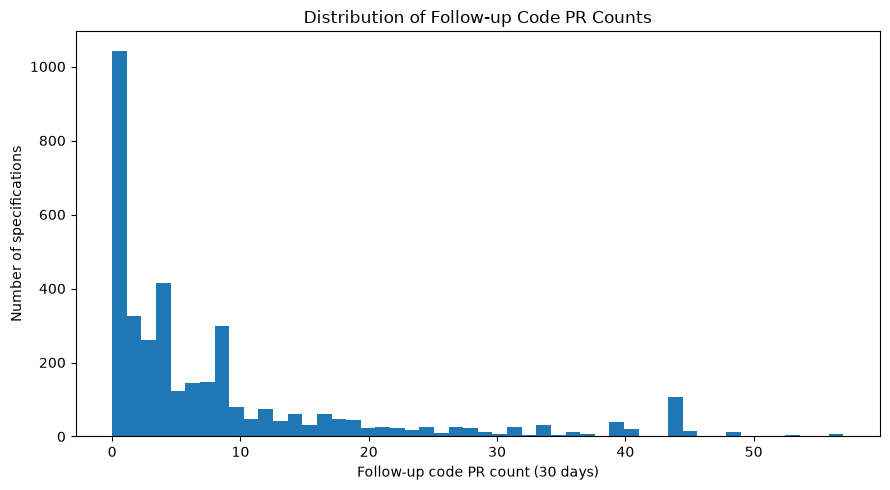

Optimization terminated successfully.
         Current function value: 3.114824
         Iterations: 13
         Function evaluations: 14
         Gradient evaluations: 14
                     NegativeBinomial Regression Results                      
Dep. Variable:     followup_fixes_30d   No. Observations:                 3729
Model:               NegativeBinomial   Df Residuals:                     3727
Method:                           MLE   Df Model:                            1
Date:                Thu, 19 Nov 2026   Pseudo R-squ.:                 0.01436
Time:                        16:21:44   Log-Likelihood:                -11615.
converged:                       True   LL-Null:                       -11784.
Covariance Type:            nonrobust   LLR p-value:                 1.416e-75
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         3.1793      0.

In [91]:
FOLLOWUP_DAYS = 30

OUTCOME = f"followup_fixes_{FOLLOWUP_DAYS}d"

analysis = spec_results.dropna(
    subset=["quality_score", OUTCOME]
).copy()

print("Outcome:", OUTCOME)
print("Observations with measurable outcome:", len(analysis))

quality_summary = (
    analysis
    .groupby("quality_score")
    [OUTCOME]
    .agg(["count", "mean", "median"])
    .reset_index()
)

print(quality_summary)

from scipy.stats import spearmanr
rho, p_value = spearmanr(
    analysis["quality_score"],
    analysis[OUTCOME]
)
print(f"Spearman correlation: {rho:.4f}")
print(f"P-value: {p_value:.6f}")

import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
plt.hist(
    analysis[OUTCOME],
    bins=50
)
plt.xlabel(f"Follow-up code PR count ({FOLLOWUP_DAYS} days)")
plt.ylabel("Number of specifications")
plt.title("Distribution of Follow-up Code PR Counts")
plt.tight_layout()
plt.show()

import statsmodels.formula.api as smf
model = smf.negativebinomial(
    f"{OUTCOME} ~ quality_score",
    data=analysis
).fit()
print(model.summary())

Negative binomial regression with control variables below

**find latest pr**

In [92]:
prs = pull_requests.copy()

prs["merged_at"] = pd.to_datetime(
    prs["merged_at"],
    errors="coerce",
    utc=True
)

print("Earliest merged PR:", prs["merged_at"].min())
print("Latest merged PR:", prs["merged_at"].max())

print("\nLatest merged PRs:")
print(
    prs.sort_values("merged_at", ascending=False)[
        ["tool", "repo_name", "pr_number", "merged_at"]
    ].head(10)
)

Earliest merged PR: 2025-08-06 07:35:05+00:00
Latest merged PR: 2026-07-14 10:42:20+00:00

Latest merged PRs:
          tool                               repo_name  pr_number  \
660   openspec  BlackBeltTechnology/pi-agent-dashboard        318   
1849  openspec                       linaproai/linapro         90   
896   openspec                       Kulitorum/Decenza       1465   
2009  openspec                       strelov1/freehire        555   
3471  openspec                       strelov1/freehire        551   
4936   speckit                            bug-ops/zeph       5901   
1393  openspec                       strelov1/freehire        545   
3673   speckit                            bug-ops/zeph       5876   
2159  openspec                       Kulitorum/Decenza       1458   
1619  openspec         Gentleman-Programming/gentle-ai       1093   

                     merged_at  
660  2026-07-14 10:42:20+00:00  
1849 2026-07-11 01:35:25+00:00  
896  2026-07-11 00:11:35+00:00 

**Controlled negative binomial regression**

In [93]:
# Restore repository metadata in analysis

metadata = (
    spec_files[["file_url_sha16", "spec_tool", "repo_name"]]
    .drop_duplicates(subset="file_url_sha16")
    .rename(columns={"spec_tool": "tool"})
)

analysis = analysis.merge(
    metadata,
    on="file_url_sha16",
    how="left",
    validate="one_to_one"
)

print("Missing tool values:", analysis["tool"].isna().sum())
print("Missing repo_name values:", analysis["repo_name"].isna().sum())

print("length of analysis: " + str(len(analysis)))

Missing tool values: 0
Missing repo_name values: 0
length of analysis: 3729


In [ ]:
# import numpy as np
# import pandas as pd
# import patsy
#
# # Inspect the data used by the regression
# print("Observations:", len(reg_data))
# print("\nTool distribution:")
# print(reg_data["tool"].value_counts())
#
# print("\nPredictor variation:")
# for col in [
#     "quality_score",
#     "log_words",
#     "log_activity",
#     "log_initial_size"
# ]:
#     print(
#         f"{col}: "
#         f"{reg_data[col].nunique()} unique values, "
#         f"std = {reg_data[col].std():.4f}"
#     )
#
# # Examine the actual design matrix for Model 1
# y, X = patsy.dmatrices(
#     formula_1,
#     reg_data,
#     return_type="dataframe"
# )
#
#
# print("\nDesign matrix columns:")
# print(X.columns.tolist())
#
# print("\nDesign matrix rank:", np.linalg.matrix_rank(X))
# print("Number of columns:", X.shape[1])
#
# if np.linalg.matrix_rank(X) < X.shape[1]:
#     print("\nWARNING: The design matrix is rank deficient.")
# else:
#     print("\nDesign matrix has full column rank.")
#
# print("length of analysis: " + str(len(analysis)))
#


**Attrition analysis**

In [ ]:
# import pandas as pd
# import numpy as np
#
# # Confirmed latest merged PR date
# DATA_CUTOFF = pd.Timestamp("2026-07-14", tz="UTC")
# FOLLOWUP_DAYS = 90
#
# attrition = analysis.copy()
#
# attrition["initial_date"] = pd.to_datetime(
#     attrition["initial_date"],
#     utc=True,
#     errors="coerce"
# )
#
# # Determine complete follow-up eligibility
# attrition["complete_followup"] = (
#     attrition["initial_date"]
#     <= DATA_CUTOFF - pd.Timedelta(days=FOLLOWUP_DAYS)
# )
#
# print("Total sample:", len(attrition))
# print("Complete follow-up:", attrition["complete_followup"].sum())
# print("Incomplete follow-up:", (~attrition["complete_followup"]).sum())
#
# # Compare retained vs excluded
# comparison = attrition.groupby("complete_followup").agg(
#     observations=("file_url_sha16", "count"),
#     mean_quality=("quality_score", "mean"),
#     median_quality=("quality_score", "median"),
#     mean_words=("n_words", "mean"),
#     median_words=("n_words", "median"),
#     mean_initial_date=("initial_date", "mean")
# )
#
# print("\nRetained vs excluded:")
# print(comparison)
#
# # Tool distributions
# print("\nTool distribution among retained:")
# print(
#     attrition.loc[attrition["complete_followup"], "tool"]
#     .value_counts()
# )
#
# print("\nTool distribution among excluded:")
# print(
#     attrition.loc[~attrition["complete_followup"], "tool"]
#     .value_counts()
# )
#
# # Quality score distributions
# print("\nQuality distribution among retained:")
# print(
#     attrition.loc[attrition["complete_followup"], "quality_score"]
#     .value_counts(normalize=True)
#     .sort_index()
# )
#
# print("\nQuality distribution among excluded:")
# print(
#     attrition.loc[~attrition["complete_followup"], "quality_score"]
#     .value_counts(normalize=True)
#     .sort_index()
# )

In [ ]:
# # ============================================================
# # LOGISTIC REGRESSION: COMPLETE FOLLOW-UP / ATTRITION
# # ============================================================
#
# import numpy as np
# import pandas as pd
# import statsmodels.formula.api as smf
#
# # Use the existing attrition dataframe from cell 18
# attrition_model_data = attrition.copy()
#
# # Convert the retention indicator to numeric (1 = retained, 0 = excluded)
# attrition_model_data["complete_followup"] = (
#     attrition_model_data["complete_followup"].astype(int)
# )
#
# # Transform specification length
# attrition_model_data["log_words"] = np.log1p(
#     attrition_model_data["n_words"]
# )
#
# # Group rare tools
# tool_counts = attrition_model_data["tool"].value_counts()
#
# common_tools = tool_counts[tool_counts >= 30].index
#
# attrition_model_data["tool_group"] = (
#     attrition_model_data["tool"].where(
#         attrition_model_data["tool"].isin(common_tools),
#         "Other"
#     )
# )
#
# # OpenSpec as reference category
# attrition_model_data["tool_group"] = pd.Categorical(
#     attrition_model_data["tool_group"],
#     categories=["openspec", "speckit", "conductor", "moai", "Other"]
# )
#
# # Fit logistic regression
# attrition_model = smf.logit(
#     "complete_followup ~ quality_score + log_words + "
#     "C(tool_group, Treatment(reference='openspec'))",
#     data=attrition_model_data
# ).fit(
#     cov_type="cluster",
#     cov_kwds={"groups": attrition_model_data["repo_name"]}
# )
#
# print(attrition_model.summary())

In [ ]:
# # Convert coefficients to odds ratios
# odds_ratios = np.exp(attrition_model.params)
#
# # Convert confidence intervals to odds-ratio scale
# ci = np.exp(attrition_model.conf_int())
#
# attrition_results = pd.DataFrame({
#     "Odds Ratio": odds_ratios,
#     "CI Lower": ci.iloc[:, 0],
#     "CI Upper": ci.iloc[:, 1],
#     "P-value": attrition_model.pvalues
# })
#
# print(attrition_results.round(4))

**Negative binomial regression models 0,1,2**

In [ ]:

# ============================================================
# CONTROLLED NEGATIVE BINOMIAL REGRESSION
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------
print("initial length of analysis: " + str(len(analysis)))

PR_KEY = ["tool", "repo_name", "pr_number"]

DATA_CUTOFF = pd.Timestamp("2026-07-14", tz="UTC")


# ------------------------------------------------------------
# 2. Validate required columns
# ------------------------------------------------------------

required_analysis = {
    "file_url_sha16",
    "tool",
    "repo_name",
    "initial_pr",
    "initial_date",
    "quality_score",
    "n_words",
    OUTCOME
}

required_prs = set(PR_KEY) | {
    "merged_at",
    "is_merged"
}

required_pr_files = set(PR_KEY) | {
    "file_path",
    "is_code"
}


def check_columns(df, required, name):
    missing = required - set(df.columns)

    if missing:
        raise ValueError(
            f"{name} missing columns: {sorted(missing)}"
        )


check_columns(analysis, required_analysis, "analysis")
check_columns(pull_requests, required_prs, "pull_requests")
check_columns(pr_files, required_pr_files, "pr_files")


# ------------------------------------------------------------
# 3. Prepare analysis dataframe
# ------------------------------------------------------------

reg_data = analysis.copy()
print("reg_data len (1): " + str(len(reg_data)))

# Ensure initial implementation dates are timezone-aware.
reg_data["initial_date"] = pd.to_datetime(
    reg_data["initial_date"],
    errors="coerce",
    utc=True
)
print("reg_data len (2): " + str(len(reg_data)))

# Convert numeric variables.
numeric_columns = [
    "quality_score",
    "n_words",
    OUTCOME,
    "initial_pr"
]

for col in numeric_columns:
    reg_data[col] = pd.to_numeric(
        reg_data[col],
        errors="coerce"
    )

# Check specification identifiers.
if reg_data["file_url_sha16"].duplicated().any():
    raise ValueError(
        "analysis contains duplicate specification IDs."
    )


# ------------------------------------------------------------
# 4. Construct initial implementation size
# ------------------------------------------------------------

# Map each specification to its initial implementation PR.
initial_map = reg_data[
    [
        "file_url_sha16",
        "tool",
        "repo_name",
        "initial_pr"
    ]
].dropna(
    subset=["tool", "repo_name", "initial_pr"]
).copy()

initial_map["initial_pr"] = (
    initial_map["initial_pr"].astype(int)
)

# Retrieve files changed in each initial implementation PR.
initial_files = initial_map.merge(
    pr_files,
    left_on=["tool", "repo_name", "initial_pr"],
    right_on=PR_KEY,
    how="left"
)

# Count distinct source-code files per specification.
initial_code_counts = (
    initial_files[
        initial_files["is_code"].eq(1)
    ]
    .groupby("file_url_sha16")["file_path"]
    .nunique()
    .rename("initial_code_file_count")
)

reg_data = reg_data.merge(
    initial_code_counts,
    on="file_url_sha16",
    how="left",
    validate="one_to_one"
)
print("reg_data len (3): " + str(len(reg_data)))

# Do not replace missing file counts with zero.
# Missing counts will be excluded from the regression.


# ------------------------------------------------------------
# 5. Construct pre-implementation repository activity
# ------------------------------------------------------------

# The PR dataset contains spec-associated PRs only.
# Therefore, this measures observed spec-associated activity,
# NOT total repository activity.

activity_prs = pull_requests.copy()

activity_prs["merged_at"] = pd.to_datetime(
    activity_prs["merged_at"],
    errors="coerce",
    utc=True
)

activity_prs = activity_prs[
    activity_prs["is_merged"].eq(1)
    & activity_prs["merged_at"].notna()
].copy()

# Deduplicate using the correct PR identity.
activity_prs = activity_prs.drop_duplicates(
    subset=PR_KEY
)

# Sort merged PR timestamps within each repository.
# Repository activity is measured across tools.
activity_groups = {
    repo: np.sort(
        group["merged_at"].astype("int64").to_numpy()
    )
    for repo, group in activity_prs.groupby("repo_name")
}

activity_counts = []

for row in reg_data.itertuples():

    if pd.isna(row.repo_name) or pd.isna(row.initial_date):
        activity_counts.append(np.nan)
        continue

    dates = activity_groups.get(
        row.repo_name,
        np.array([], dtype=np.int64)
    )

    end = row.initial_date.value

    start = (
        row.initial_date
        - pd.Timedelta(days=FOLLOWUP_DAYS)
    ).value

    # Count merged spec-associated PRs in the preceding 90 days.
    count = (
        np.searchsorted(dates, end, side="left")
        - np.searchsorted(dates, start, side="left")
    )

    activity_counts.append(count)

reg_data["spec_associated_activity_90d"] = (
    activity_counts
)


# ------------------------------------------------------------
# 6. Restrict to complete 90-day observation windows
# ------------------------------------------------------------

complete_window_end = (
    DATA_CUTOFF - pd.Timedelta(days=FOLLOWUP_DAYS)
)

n_before_window = len(reg_data)

reg_data = reg_data[
    reg_data["initial_date"].notna()
    & (reg_data["initial_date"] <= complete_window_end)
].copy()

print(
    "Removed for incomplete 90-day window:",
    n_before_window - len(reg_data)
)


# ------------------------------------------------------------
# 7. Handle missing values
# ------------------------------------------------------------

model_variables = [
    "file_url_sha16",
    "repo_name",
    "tool",
    "quality_score",
    "n_words",
    "initial_code_file_count",
    "spec_associated_activity_90d",
    "followup_fixes_90d"
]

print("\nMissing values before filtering:")
print(reg_data[model_variables].isna().sum())

n_before_missing = len(reg_data)

# Complete-case analysis.
reg_data = reg_data.dropna(
    subset=model_variables
).copy()

print(
    "\nRemoved due to missing model variables:",
    n_before_missing - len(reg_data)
)


# ------------------------------------------------------------
# 8. Validate variables
# ------------------------------------------------------------

assert (reg_data["n_words"] > 0).all()

assert (reg_data["initial_code_file_count"] > 0).all()

assert (reg_data["spec_associated_activity_90d"] >= 0).all()

assert (reg_data["followup_fixes_90d"] >= 0).all()

assert (reg_data["quality_score"] >= 0).all()

# Ensure outcome is integer-valued.
assert np.allclose(
    reg_data["followup_fixes_90d"],
    reg_data["followup_fixes_90d"].round()
)

reg_data["followup_fixes_90d"] = (
    reg_data["followup_fixes_90d"].astype(int)
)


# ------------------------------------------------------------
# 9. Construct control-variable transformations
# ------------------------------------------------------------

# Log transformations reduce skewness and make the
# coefficients easier to interpret proportionally.

reg_data["log_words"] = np.log1p(
    reg_data["n_words"]
)

reg_data["log_activity"] = np.log1p(
    reg_data["spec_associated_activity_90d"]
)

reg_data["log_initial_size"] = np.log1p(
    reg_data["initial_code_file_count"]
)


# ------------------------------------------------------------
# 10. Define regression models
# ------------------------------------------------------------

# Exclude tools with fewer than 30 observations
tool_counts = reg_data["tool"].value_counts()

common_tools = tool_counts[tool_counts >= 30].index

reg_data = reg_data[
    reg_data["tool"].isin(common_tools)
].copy()

print("Tool distribution:")
print(reg_data["tool"].value_counts())


# Regression formulas

formula_0 = """
followup_fixes_90d ~ quality_score
"""

formula_1 = """
followup_fixes_90d ~ quality_score
+ log_words
+ C(tool, Treatment(reference='openspec'))
"""

formula_2 = """
followup_fixes_90d ~ quality_score
+ log_words
+ C(tool, Treatment(reference='openspec'))
+ log_initial_size
"""

# ------------------------------------------------------------
# 11. Fit negative binomial models
# ------------------------------------------------------------

def fit_negative_binomial(formula, data):

    model = smf.negativebinomial(
        formula=formula,
        data=data
    )

    result = model.fit(
        method="bfgs",
        maxiter=500,
        disp=False,
        cov_type="cluster",
        cov_kwds={
            "groups": data["repo_name"]
        }
    )

    if not result.mle_retvals.get("converged", False):
        print("WARNING: Model did not converge.")

    return result


model_0 = fit_negative_binomial(
    formula_0,
    reg_data
)

model_1 = fit_negative_binomial(
    formula_1,
    reg_data
)

model_2 = fit_negative_binomial(
    formula_2,
    reg_data
)


# ------------------------------------------------------------
# 12. Display regression summaries
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MODEL 0: UNCONTROLLED")
print("=" * 65)
print(model_0.summary())

print("\n" + "=" * 65)
print("MODEL 1: PRIMARY CONTROLLED MODEL")
print("=" * 65)
print(model_1.summary())

print("\n" + "=" * 65)
print("MODEL 2: INCLUDING IMPLEMENTATION SIZE")
print("=" * 65)
print(model_2.summary())


# ------------------------------------------------------------
# 13. Compare quality coefficients across models
# ------------------------------------------------------------

models = {
    "M0: Uncontrolled": model_0,
    "M1: Primary controls": model_1,
    "M2: Including implementation size": model_2
}

comparison_rows = []

for name, model in models.items():

    coefficient = model.params["quality_score"]

    confidence_interval = model.conf_int().loc[
        "quality_score"
    ]

    irr = np.exp(coefficient)

    comparison_rows.append({

        "Model": name,

        "Coefficient": coefficient,

        "IRR": irr,

        "IRR_CI_lower": np.exp(
            confidence_interval.iloc[0]
        ),

        "IRR_CI_upper": np.exp(
            confidence_interval.iloc[1]
        ),

        "Percent_change": (irr - 1) * 100,

        "P_value": model.pvalues["quality_score"],

        "Observations": int(model.nobs),

        "Pseudo_R2": model.prsquared
    })


model_comparison = pd.DataFrame(
    comparison_rows
)

print("\n" + "=" * 65)
print("QUALITY COEFFICIENT COMPARISON")
print("=" * 65)

print(
    model_comparison.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# 14. Sample diagnostics
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL SAMPLE DIAGNOSTICS")
print("=" * 65)

print("Observations:", len(reg_data))

print("Repositories:", reg_data["repo_name"].nunique())

print("Tools:", reg_data["tool"].nunique())

print(
    "Mean follow-up PR count:",
    round(reg_data["followup_fixes_90d"].mean(), 3)
)

print(
    "Variance of follow-up PR count:",
    round(reg_data["followup_fixes_90d"].var(), 3)
)

print("\nSpecifications by tool:")
print(reg_data["tool"].value_counts())

print("\nSpecifications by quality score:")
print(reg_data["quality_score"].value_counts().sort_index())

print("\nRepository cluster sizes:")
print(reg_data.groupby("repo_name").size().describe())
